# Prévoir les fûts — Brasserie de la Fonderie

Jour 5 · jeudi 26 novembre 2026. Données fictives.

Les cellules de démonstration sont déjà écrites : exécutez-les (Ctrl+Entrée), modifiez-les. Les exercices s'écrivent dans les cellules vides.

Avant de rendre : « Restart », puis « Run All ».

## 0. Mise en route (J5-08)

Dans `data/` : `ventes_semaine.csv` (hier soir) et `agenda.csv`. Dans `notebooks/` : ce notebook et `reseau.py`.

In [1]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

tableau = pd.read_csv("../data/ventes_semaine.csv", sep=";")
print(len(tableau), "semaines,", tableau["futs"].sum(), "fûts")      # contrôle : 51 semaines, 896 fûts

51 semaines, 896 fûts


## 1. Un premier modèle (J5-12 à J5-16)

In [2]:
tableau["numero"] = range(len(tableau))
entrainement, test = tableau.iloc[:40], tableau.iloc[40:]
print(len(entrainement), len(test))

40 11


La référence à battre : dire la moyenne de l'entraînement, chaque semaine.

In [3]:
moyenne = entrainement["futs"].mean()
erreur = mean_absolute_error(test["futs"], [moyenne] * len(test))
print(round(moyenne, 2), round(erreur, 2))

17.62 3.92


In [4]:
modele = LinearRegression()
modele.fit(entrainement[["numero"]], entrainement["futs"])
prevision = modele.predict(test[["numero"]])
print(prevision.round(1).tolist())
print(test["futs"].tolist())

[18.6, 18.6, 18.7, 18.7, 18.8, 18.8, 18.9, 18.9, 19.0, 19.0, 19.1]
[14, 33, 14, 16, 17, 15, 14, 22, 18, 12, 16]


In [5]:
print(round(mean_absolute_error(test["futs"], prevision), 2))
print(test["futs"].tolist())

4.64
[14, 33, 14, 16, 17, 15, 14, 22, 18, 12, 16]


## 2. Ce que la brasserie sait à l'avance (J5-18 à J5-20)

`agenda.csv` : `comite` vaut 1 les semaines où le Comité des fêtes d'Ougrée a réservé ses fûts à l'avance.

In [6]:
agenda = pd.read_csv("../data/agenda.csv", sep=";")
tableau = tableau.merge(agenda, on="semaine")
print(tableau.shape, tableau["comite"].sum())

(51, 4) 3


In [22]:
entrainement, test = tableau.iloc[:40], tableau.iloc[40:]
colonnes = ["numero", "comite"]
modele = LinearRegression().fit(entrainement[colonnes], entrainement["futs"])
print(round(mean_absolute_error(test["futs"], modele.predict(test[colonnes])), 2))
print(modele.coef_.round(2).tolist(), round(modele.intercept_, 2))

2.99
[0.05, 14.13] 15.89


In [8]:
semaine = pd.DataFrame({"numero": [52, 52], "comite": [0, 1]})
print(modele.predict(semaine).round(1).tolist())

[18.6, 32.8]


### Exercices 1.1 à 1.5 (J5-22)

**1.1** La cellule ci-dessous plante. Décommentez-la, exécutez-la, lisez le message, corrigez-la.

In [ ]:
# modele_11 = LinearRegression()
# modele_11.fit(entrainement["numero"], entrainement["futs"])
modele_11 = LinearRegression()
modele_11.fit(entrainement[["numero"]], entrainement["futs"])      # doubles crochets : X est un tableau
print("ça marche")

**1.2** Entraînez avec `comite` seul. Quelle erreur sur le test ?

In [ ]:
# Votre code ici
modele_comite = LinearRegression().fit(entrainement[["comite"]], entrainement["futs"])
print(round(mean_absolute_error(test["futs"], modele_comite.predict(test[["comite"]])), 2))

**1.3** Avec `numero` seul et avec `comite` seul : lequel est le meilleur, et pourquoi ? (réponse en commentaire)

In [ ]:
# Votre code ici
for choix in [["numero"], ["comite"]]:
    m = LinearRegression().fit(entrainement[choix], entrainement["futs"])
    print(choix, round(mean_absolute_error(test["futs"], m.predict(test[choix])), 2))

**1.4** Avec le modèle de 1.2 (`comite` seul), prévoyez la semaine 52, sans puis avec réservation.

In [ ]:
# Votre code ici
print(modele_comite.predict(pd.DataFrame({"comite": [0, 1]}))
      .round(1).tolist())

**1.5** (bonus) Ajoutez la colonne « fûts de la semaine d'avant » (`shift`), entraînez avec `numero` et cette colonne, mesurez. La première semaine n'a pas de semaine d'avant : entraînez sur `tableau.iloc[1:40]`, testez sur `tableau.iloc[40:]`.

In [ ]:
# Votre code ici
tableau["semaine_avant"] = tableau["futs"].shift()
choix = ["numero", "semaine_avant"]
ent_15, test_15 = tableau.iloc[1:40], tableau.iloc[40:]
m = LinearRegression().fit(ent_15[choix], ent_15["futs"])
print(round(mean_absolute_error(test_15["futs"], m.predict(test_15[choix])), 2))

## 3. Un réseau de neurones (J5-43 à J5-49)

In [14]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

reseau = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(10,), random_state=0),
)
reseau.fit(entrainement[colonnes], entrainement["futs"])

c:\Users\fck-t\Documents\development\Fonderie\fonderie-python\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('mlpregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](2,)","['numero','comite']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


Un avertissement `ConvergenceWarning` : 200 passages sur les 40 semaines ne suffisent pas. On en donne plus.

In [15]:
reseau = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(10,), max_iter=5000, random_state=0),
)
reseau.fit(entrainement[colonnes], entrainement["futs"])
print(reseau[-1].n_iter_, "passages")

3287 passages


In [16]:
for nom, partie in [("ent", entrainement), ("test", test)]:
    p = reseau.predict(partie[colonnes])
    print(nom, round(mean_absolute_error(partie["futs"], p), 2))

ent 2.97
test 9.04


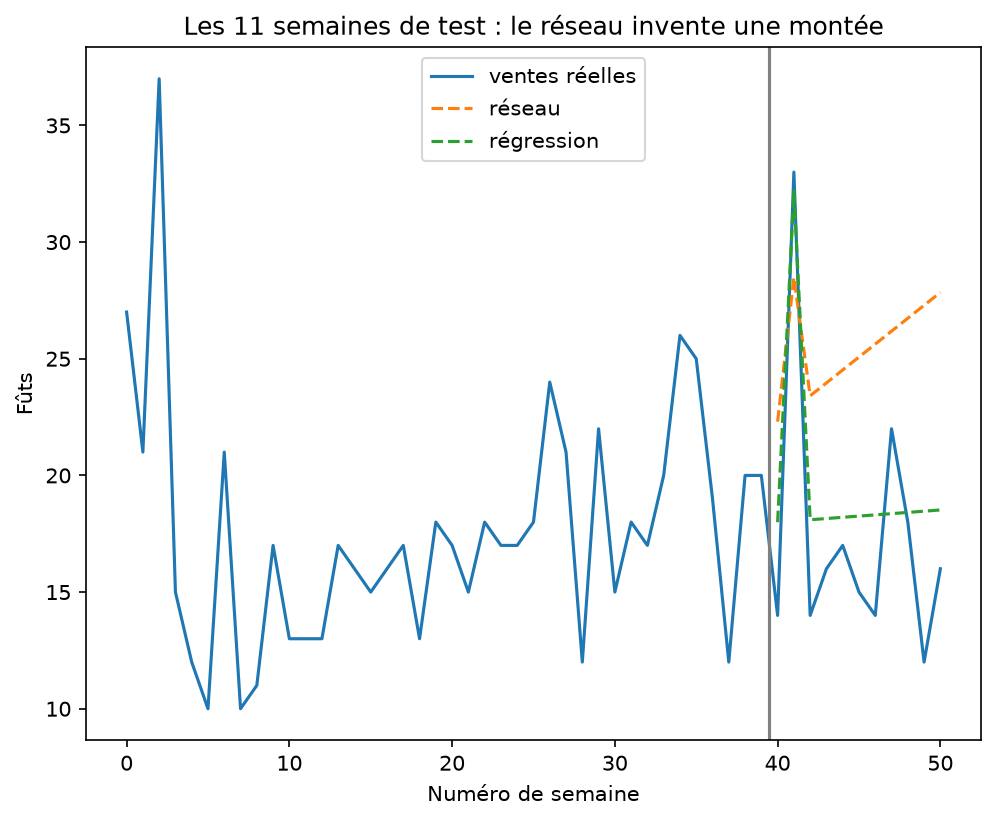

In [17]:
import matplotlib.pyplot as plt

regression = LinearRegression().fit(entrainement[colonnes], entrainement["futs"])
plt.figure(figsize=(7.7, 6), dpi=150)
plt.plot(tableau["numero"], tableau["futs"], label="ventes réelles")
plt.plot(test["numero"], reseau.predict(test[colonnes]), "--", label="réseau")
plt.plot(test["numero"], regression.predict(test[colonnes]), "--", label="régression")
plt.axvline(39.5, color="grey")
plt.title("Les 11 semaines de test : le réseau invente une montée")
plt.xlabel("Numéro de semaine")
plt.ylabel("Fûts")
plt.legend()
plt.show()

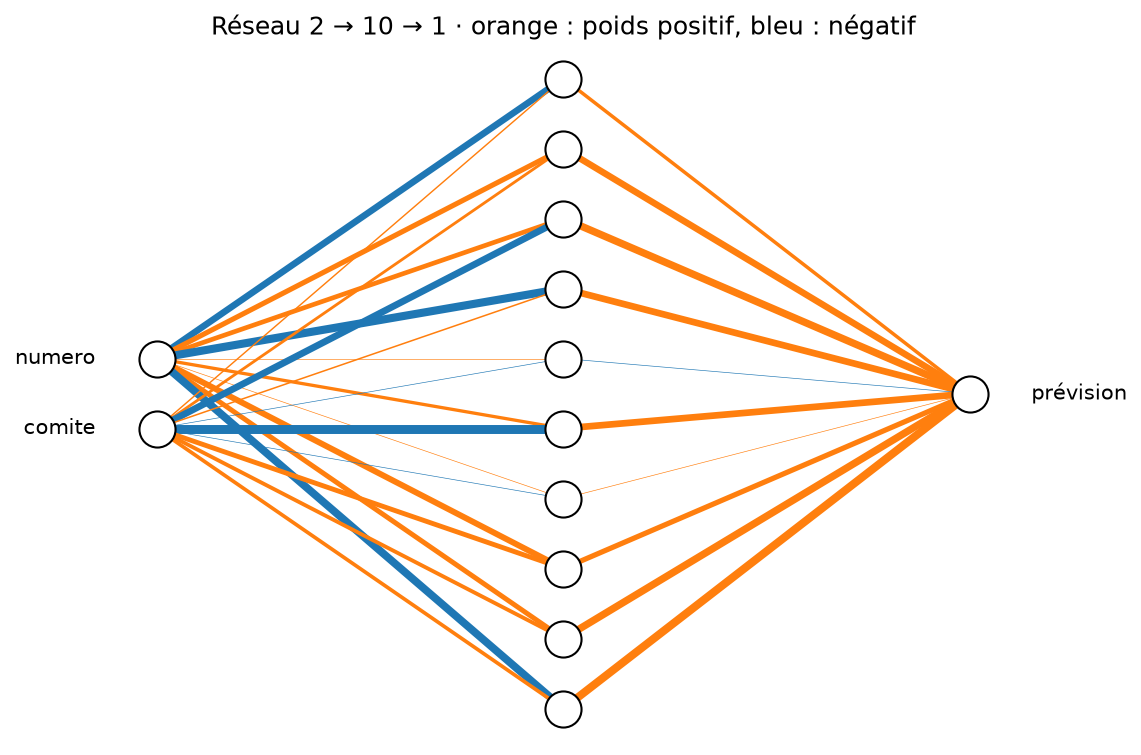

In [18]:
from reseau import dessiner_reseau

dessiner_reseau(reseau, ["numero", "comite"])

Sans `numero` : le réseau ne voit plus que l'agenda.

In [19]:
reseau.fit(entrainement[["comite"]], entrainement["futs"])
print(round(mean_absolute_error(test["futs"], reseau.predict(test[["comite"]])), 2))

2.31


### Exercice 2 (J5-51)

Avec `colonnes = ["numero", "comite"]`, `max_iter=5000` et `random_state=0` : erreur de test pour `hidden_layer_sizes` = (1,), (3,), (10,), (50,), (10, 10). Redessinez le meilleur. Une taille bat-elle la régression (2,99) ?

Votre tableau de résultats :

In [20]:
# Votre code ici


## Bonus : un neurone qui apprend tout seul (J5-R1)

Une descente de gradient en Python pur, sans scikit-learn. Entrée : `comite` ; sortie : les fûts. Comparez avec `modele_comite.coef_` et `modele_comite.intercept_` (exercice 1.2).

In [21]:
x = entrainement["comite"].tolist()
y = entrainement["futs"].tolist()

poids, biais, pas = 0.0, 0.0, 0.05
for passe in range(2000):
    dp = db = 0.0
    for xi, yi in zip(x, y):
        ecart = (poids * xi + biais) - yi      # erreur de la prévision
        dp += 2 * ecart * xi / len(x)            # dans quel sens bouger le poids
        db += 2 * ecart / len(x)                 # et le biais
    poids -= pas * dp
    biais -= pas * db
print(round(poids, 2), round(biais, 2))

14.08 16.92
